In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import joblib

In [2]:
df=pd.read_csv(r"../data/cleaned_household_energy.csv")

In [3]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [4]:
df.head()

,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh,Year,Month,Day,DayOfWeek
0,8.4,4,17.8,No,3.2,2025,4,1,1
1,7.9,4,17.3,No,2.8,2025,4,2,2
2,9.2,4,18.6,No,3.0,2025,4,3,3
3,7.9,4,18.2,No,2.7,2025,4,4,4
4,9.6,4,11.9,No,3.2,2025,4,5,5


In [5]:
df.shape

(90000, 9)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Energy_Consumption_kWh  90000 non-null  float64
 1   Household_Size          90000 non-null  int64  
 2   Avg_Temperature_C       90000 non-null  float64
 3   Has_AC                  90000 non-null  str    
 4   Peak_Hours_Usage_kWh    90000 non-null  float64
 5   Year                    90000 non-null  int64  
 6   Month                   90000 non-null  int64  
 7   Day                     90000 non-null  int64  
 8   DayOfWeek               90000 non-null  int64  
dtypes: float64(3), int64(5), str(1)
memory usage: 6.2 MB


In [7]:
#convert categorical data into numerical
df["Has_AC"] = LabelEncoder().fit_transform(df["Has_AC"])
#or we can simply map
#df["Has_AC"] = df["Has_AC"].map({"No": 0, "Yes": 1})

In [8]:
df['Has_AC'].value_counts()

Has_AC
0    45508
1    44492
Name: count, dtype: int64

In [9]:
#feature defining
X=df.drop("Energy_Consumption_kWh",axis=1)
y=df['Energy_Consumption_kWh']

print("Features\n",X.head())
print("Target\n",y.head())

Features
    Household_Size  Avg_Temperature_C  Has_AC  Peak_Hours_Usage_kWh  Year  \
0               4               17.8       0                   3.2  2025   
1               4               17.3       0                   2.8  2025   
2               4               18.6       0                   3.0  2025   
3               4               18.2       0                   2.7  2025   
4               4               11.9       0                   3.2  2025   

   Month  Day  DayOfWeek  
0      4    1          1  
1      4    2          2  
2      4    3          3  
3      4    4          4  
4      4    5          5  
Target
 0    8.4
1    7.9
2    9.2
3    7.9
4    9.6
Name: Energy_Consumption_kWh, dtype: float64


In [10]:
#80-20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (72000, 8)
Testing Features: (18000, 8)
Training Target: (72000,)
Testing Target: (18000,)


In [11]:
#Linear Regression
lr=LinearRegression()
lr.fit(X_train,y_train)
y_pred_lr=lr.predict(X_test)

In [12]:
lr_r2 = r2_score(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = mean_squared_error(y_test, y_pred_lr) ** 0.5

print("Linear Regression Performance")
print("-----------------------------")
print(f"R² Score : {lr_r2:.4f}")
print(f"MAE      : {lr_mae:.4f}")
print(f"RMSE     : {lr_rmse:.4f}")

Linear Regression Performance
-----------------------------
R² Score : 0.9795
MAE      : 0.6272
RMSE     : 0.7894


In [13]:
#Random Forest
#Helps to tell which feature were most imp in determining the output
rf=RandomForestRegressor(random_state=42)
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)

In [14]:
rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = mean_squared_error(y_test, y_pred_rf) ** 0.5

print("Random Forest Performance")
print("-------------------------")
print(f"R² Score : {rf_r2:.4f}")
print(f"MAE      : {rf_mae:.4f}")
print(f"RMSE     : {rf_rmse:.4f}")

Random Forest Performance
-------------------------
R² Score : 0.9828
MAE      : 0.5298
RMSE     : 0.7244


In [15]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R² Score": [lr_r2, rf_r2],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse]
})
comparison

,Model,R² Score,MAE,RMSE
0,Linear Regression,0.979540,0.627162,0.789355
1,Random Forest,0.982768,0.529843,0.724415


Random Forest performs better than Linear Regression

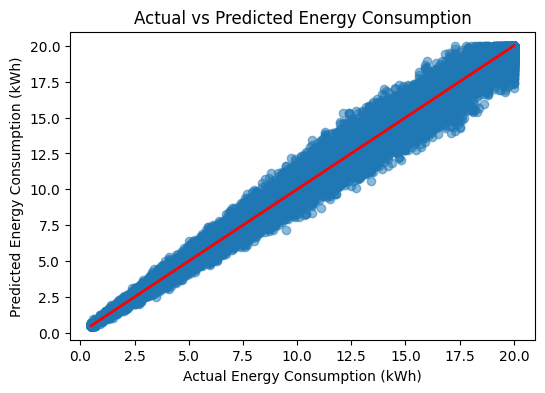

In [16]:
plt.figure(figsize=(6,4))
plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)
plt.xlabel("Actual Energy Consumption (kWh)")
plt.ylabel("Predicted Energy Consumption (kWh)")
plt.title("Actual vs Predicted Energy Consumption")
plt.show()

In [17]:
#Extracting imp features
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
feature_importance

,Feature,Importance
3,Peak_Hours_Usage_kWh,0.944102
0,Household_Size,0.041420
1,Avg_Temperature_C,0.007708
2,Has_AC,0.003601
6,Day,0.001587
7,DayOfWeek,0.001582
5,Month,0.000000
4,Year,0.000000


In [18]:
df.columns

Index(['Energy_Consumption_kWh', 'Household_Size', 'Avg_Temperature_C',
       'Has_AC', 'Peak_Hours_Usage_kWh', 'Year', 'Month', 'Day', 'DayOfWeek'],
      dtype='str')

In [ ]:
joblib.dump(rf, "../models/energy_model.pkl")
#for deployment in streamlit application
print("Model saved successfully!")

Model saved successfully!


In [20]:
loaded_model = joblib.load("../models/energy_model.pkl")
loaded_model.predict(X_test.head())

array([14.964     ,  7.30266667, 11.731     ,  8.51008333, 16.81183333])